# 3 · Application

This notebook is prepared to showcase part of my research the application side of it. 

**Question**: We are trying to answer how climate signals co-occur with mobility of people. We have open-source Call Data Records (CDR) that we use to build inference.

For this activity, we use **xvec** to turn a climate data cube into **zones** (one value per spatial-unit polygon and time step), then explore the result as zonal maps and time series with the plotting module `adaptive_cube_plot`. Mobility comparison is an optional final section and is switched off by default.

| Step | Result |
|---|---|
| Load cube and spatial units | Confirm matching coordinates and CRS |
| `xvec.zonal_stats` | A vector data cube: one climate statistic per zone and time |
| `plot_zonal_maps` | A single-date zonal map and a shared-scale panel for several time slices |
| `plot_zonal_timeseries` | Selected zones highlighted on a locator map next to their time series |
| Optional | `plot_spatial_timeseries` pixel check, and `plot_climate_mobility_period` |




> Start with a short time window and a regional cube. Exact extraction can take time over long records. `exactextract` uses fractional pixel coverage; the fallback `rasterize` method is faster but may omit small polygons or approximate their boundaries. xvec requires the geometries and raster coordinates to use the same CRS. [xvec zonal statistics documentation](https://xvec.readthedocs.io/en/latest/generated/xarray.DataArray.xvec.zonal_stats.html).

## 1 · Load the cube and zone polygons

This cell opens one Zarr store, reads the spatial-unit Parquet file, and limits processing to the cube footprint. If needed, set `START_DATE` and `END_DATE` to a smaller pilot period before extracting.

In [11]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xvec  # registers the .xvec accessor
import rioxarray  # needed by the exactextract backend
from shapely.geometry import box

# Find the repository root from the current notebook directory.
REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "pyproject.toml").exists())
DATA = REPO / "data"

# Plot helpers from this repository: code/plot_utils/adaptive_cube_plot.py
sys.path.insert(0, str(REPO / "code" / "plot_utils"))
from adaptive_cube_plot import (plot_climate_mobility_period, plot_spatial_timeseries,
                                plot_zonal_maps, plot_zonal_timeseries)
MAP_CONTEXT = True  # coastlines/borders on maps; Natural Earth data is downloaded on first use
PRODUCT = "METREF"  # e.g. METREF or FVC; must match the Zarr data variable
ZONE_FILE = DATA / "aoi" / "spatial_units_with_lat_lon.parquet"
START_DATE = None  # e.g. "2013-01-01"; None means all available dates
END_DATE = None    # e.g. "2015-12-31"

stores = sorted(p for p in (DATA / "zarr").glob("*.zarr") if (p / "zarr.json").exists())
if not stores:
    raise FileNotFoundError("No Zarr v3 store found under data/zarr; build the cube first.")
store = next((p for p in stores if PRODUCT.lower() in p.name.lower()), stores[0])
ds = xr.open_zarr(store, consolidated=False)
if PRODUCT not in ds:
    raise KeyError(f"{PRODUCT!r} not in {list(ds.data_vars)}")

# Standardize common coordinate names if this cube uses other names.
rename = {old: new for old, new in {"latitude": "lat", "longitude": "lon",
                                    "y": "lat", "x": "lon"}.items()
          if old in ds.dims or old in ds.coords}
ds = ds.rename(rename)
required = {"time", "lat", "lon"}
if not required.issubset(ds[PRODUCT].dims):
    raise ValueError(f"Expected {required} dimensions; found {ds[PRODUCT].dims}")

# Read polygon geometries from WKB Parquet (as in this tutorial's input data).
units_df = pd.read_parquet(ZONE_FILE)
if "geometry" in units_df and len(units_df) and isinstance(units_df.geometry.iloc[0], (bytes, bytearray, memoryview)):
    import shapely
    geometry = shapely.from_wkb(units_df.pop("geometry").to_numpy())
    units = gpd.GeoDataFrame(units_df, geometry=geometry, crs="EPSG:4326")
else:
    units = gpd.GeoDataFrame(units_df, geometry="geometry", crs="EPSG:4326")
if units.crs is None:
    raise ValueError("Spatial-unit CRS is missing; set the correct CRS before continuing.")
units = units.to_crs("EPSG:4326")
if "norm_id" not in units or units["norm_id"].duplicated().any():
    raise ValueError("Spatial units need a unique 'norm_id' column.")

# Trim to the time window before zonal extraction to keep the pilot manageable.
da = ds[PRODUCT].sel(time=slice(START_DATE, END_DATE))
if da.sizes.get("time", 0) == 0:
    raise ValueError("No time steps in the requested date range.")
# Include half a cell around the outer coordinate centers when selecting zones.
dx = float(np.median(np.abs(np.diff(ds.lon.values))))
dy = float(np.median(np.abs(np.diff(ds.lat.values))))
cube_footprint = box(float(ds.lon.min())-dx/2, float(ds.lat.min())-dy/2,
                     float(ds.lon.max())+dx/2, float(ds.lat.max())+dy/2)
units_in = units.loc[units.geometry.intersects(cube_footprint)].copy()
if units_in.empty:
    raise ValueError("No spatial units intersect the cube extent.")
print(f"Store: {store.name} | {dict(ds.sizes)}")
print(f"Zones intersecting cube: {len(units_in)} / {len(units)}")
print(f"Period: {pd.Timestamp(da.time.values[0]).date()} to {pd.Timestamp(da.time.values[-1]).date()}")

Store: metref_cube.zarr | {'time': 31, 'lat': 91, 'lon': 121}
Zones intersecting cube: 151 / 151
Period: 2010-01-01 to 2010-01-31


## 2 · Create zones with xvec

The spatial units become the **zones**. We pass the polygons to xvec once and ask for a spatial mean. The result is a *vector data cube*: the raster dimensions `lat`/`lon` are replaced by one `zone` dimension whose index holds the polygon geometries, and `time` is kept. The zone ID `norm_id` stays attached as a coordinate, so results can be joined back to other tables.

`exactextract` is preferred for fractional pixel coverage. If it is unavailable, the cell uses `rasterize` and reports that choice. With the fallback, cells are assigned by their centers (`all_touched=False`); small zones can have no cells, so inspect missing values.

The cube is passed to xvec with `x`/`y` dimension names, because the `exactextract` backend looks for those spatial dimension names.

In [12]:
# xvec needs matching CRS. This cube's lon/lat coordinates and zones are EPSG:4326.
zone_geometries = units_in.set_index("norm_id").geometry
try:
    import exactextract  # noqa: F401
    ZONAL_METHOD = "exactextract"
except ImportError:
    ZONAL_METHOD = "rasterize"

zonal = da.rename(lon="x", lat="y").xvec.zonal_stats(
    geometry=zone_geometries,
    x_coords="x",
    y_coords="y",
    stats="mean",
    name="zone",
    index=True,
    method=ZONAL_METHOD,
    all_touched=False,
).rename("zonal_mean").load()

n_missing = int(zonal.isnull().all("time").sum())
print("xvec method:", ZONAL_METHOD)
print(f"Zones: {zonal.sizes['zone']} | time steps: {zonal.sizes['time']} | "
      f"zones with no value at any time: {n_missing}")
zonal

xvec method: exactextract
Zones: 151 | time steps: 31 | zones with no value at any time: 0


<xarray.DataArray 'zonal_mean' (zone: 151, time: 31)> Size: 37kB
array([[3.35583243, 3.41356143, 2.98552109, ..., 3.73618504, 3.79189725,
        3.75063212],
       [3.25383186, 3.47967267, 3.35512111, ..., 3.74088438, 3.61785183,
        3.39395626],
       [3.28447016, 3.4470687 , 3.22372596, ..., 3.73581865, 3.64565971,
        3.51781246],
       ...,
       [3.43664249, 3.53029949, 3.1031431 , ..., 3.78477841, 3.84120781,
        3.50400954],
       [3.48780884, 3.61533603, 3.45140193, ..., 4.06953716, 4.14447926,
        3.25691039],
       [3.15908202, 3.58363053, 3.45239404, ..., 3.98672616, 4.07794498,
        3.30199723]], shape=(151, 31))
Coordinates:
  * zone     (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.57827377, -17...
    norm_id  (zone) object 1kB 'sen.1.1.1' 'sen.10.1.1' ... 'city-054'
  * time     (time) datetime64[ns] 248B 2010-01-01 2010-01-02 ... 2010-01-31
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    long_name:  METREF
    units:      mm/day

## 3 · Zonal maps for a few time slices

`plot_zonal_maps` draws the zonal cube straight from xvec: polygons come from the `zone` geometry index, so no join back to a table is needed. One time index gives a single map; several give a panel. Panels share one color scale and one colorbar, use the module's `VAR_CMAP`, and are drawn in a local Cartopy projection. Zones without a value are hatched grey.

Choose the time slices with `N_SLICES` (evenly spaced over the period) or set `DATES` to your own list; dates are matched to the nearest available time step.

In [24]:
UNITS = da.attrs.get("units", "units not recorded")
LABEL = f"{PRODUCT} zonal mean"
N_SLICES = 10        # evenly spaced time slices over the period
DATES = None        # or e.g. ["2020-06-01", "2020-06-15", "2020-06-30"]
PANEL_COLS = 2

if DATES is None:
    SLICE_IDX = sorted(set(np.linspace(0, zonal.sizes["time"] - 1, N_SLICES).round().astype(int).tolist()))
else:
    SLICE_IDX = sorted(set(pd.Index(zonal.time.values).get_indexer(pd.to_datetime(DATES), method="nearest").tolist()))
print("Time slices:", ", ".join(str(pd.Timestamp(zonal.time.values[i]).date()) for i in SLICE_IDX))

Time slices: 2010-01-01, 2010-01-04, 2010-01-08, 2010-01-11, 2010-01-14, 2010-01-18, 2010-01-21, 2010-01-24, 2010-01-28, 2010-01-31


### Single zonal map

Each polygon is colored by the mean of the selected climate variable across its included cells. This is a **zonal summary**, not a higher-resolution map of the original raster.

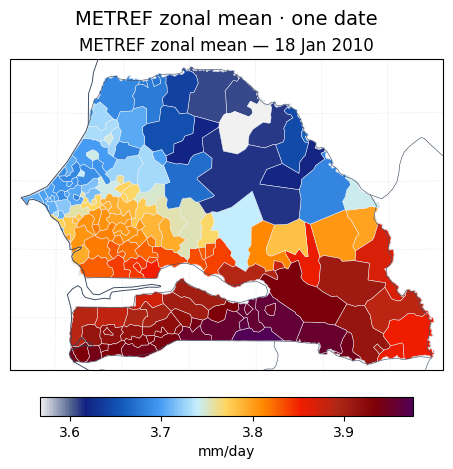

In [26]:
fig, axes = plot_zonal_maps(
    zonal, var=LABEL, time_index=SLICE_IDX[len(SLICE_IDX) // 2],
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT, title=f"{LABEL} · one date",
)

### Several time slices in one panel

The same function with all selected time indices. Use a few dates to inspect change; plotting every daily date would make an unwieldy figure. Pass `vmin`/`vmax` for fixed limits, or `robust=True` to clip the scale at the 2nd and 98th percentile.

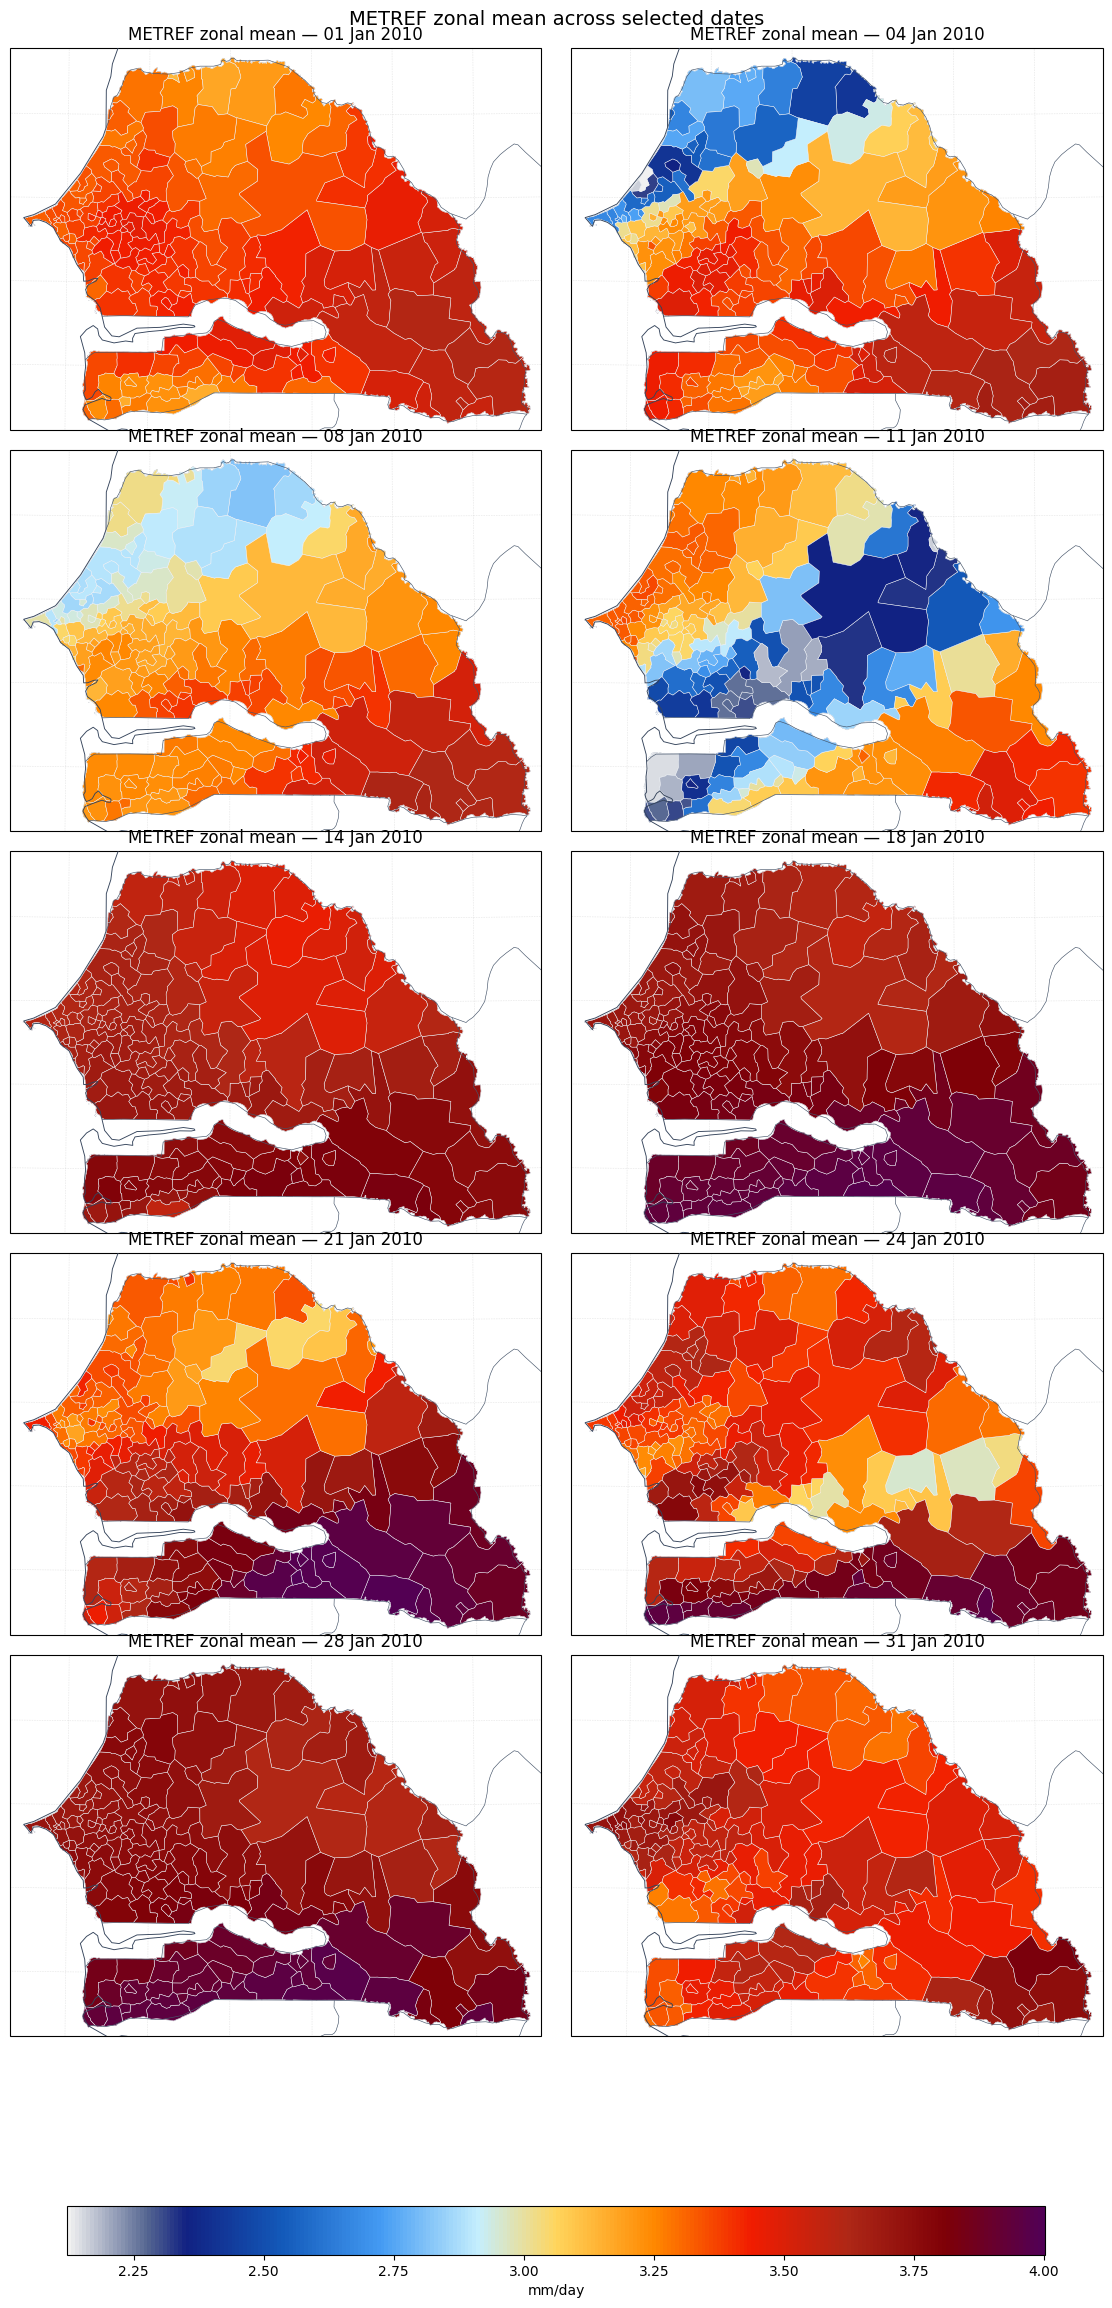

In [27]:
fig, axes = plot_zonal_maps(
    zonal, var=LABEL, time_index=SLICE_IDX, ncols=PANEL_COLS,
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT, title=f"{LABEL} across selected dates",
)

## 4 · Zone time series with a locator map

`plot_zonal_timeseries` plots the zonal mean through time for selected zones. A locator map shows where they are, in the same colors as the lines. By default it picks the zones with the lowest, median, and highest period mean; set `SELECTED_IDS` to your own `norm_id` values to override this. If the full period is long, first set `START_DATE` and `END_DATE` above to a suitable window.

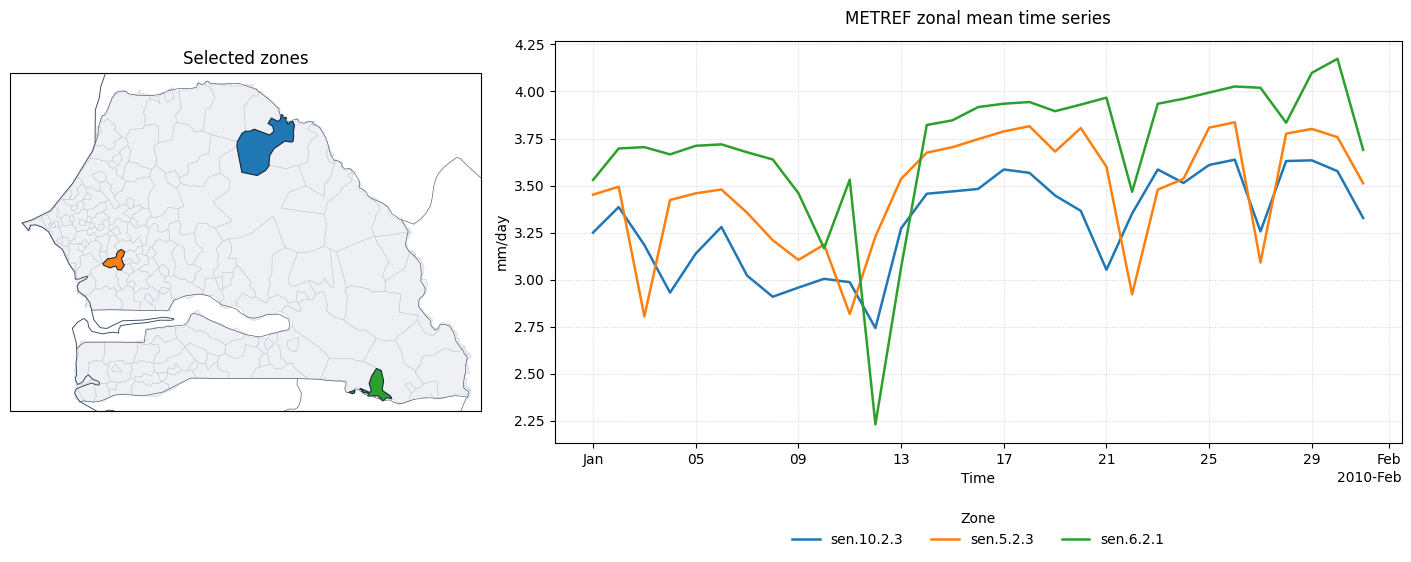

Zones: ['sen.10.2.3', 'sen.5.2.3', 'sen.6.2.1']


In [17]:
SELECTED_IDS = None   ## could be a zone value or unit id

fig, axes = plot_zonal_timeseries(
    zonal, var=LABEL, zones=SELECTED_IDS, id_coord="norm_id",
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT, title=f"{LABEL} time series",
)
SELECTED_IDS = axes["zones"]   # the zones that were plotted
print("Zones:", SELECTED_IDS)

### Optional: pixel-level check

`plot_spatial_timeseries` samples the raw cube at a point. Here it uses one point inside each selected zone, so you can compare a single pixel with the zonal mean above. The two should follow the same seasonal shape; a large offset means the zone mean is dominated by other pixels.

In [23]:
# zone_points = (units_in.assign(_id=units_in["norm_id"].astype(str)).set_index("_id")
#                .loc[SELECTED_IDS].geometry.representative_point())
# plot_spatial_timeseries(
#     ds, points={zid: (pt.x, pt.y) for zid, pt in zone_points.items()},
#     var="METREF",
#     title=f"{PRODUCT} at one pixel inside each selected zone",
# )

## 5 · Optional mobility comparison

Mobility is not required for the climate zonal workflow. Set `RUN_MOBILITY = True` only when the mobility file and filters are available. `plot_climate_mobility_period` shows the climate map of the half-month that contains `MOBILITY_DATE` next to mobility totals per origin polygon. Dates are grouped into days 1-15 and 16-month end. Confirm that the mobility spatial IDs and periods use the same definitions as the climate data before interpreting a comparison.

In [ ]:
RUN_MOBILITY = False
MOBILITY_FILE = DATA / "aoi" / "mobility_data_processed.parquet"
MOBILITY_DATE = "2015-06-01"  # a date whose half-month is present in both datasets
METRIC = "rate_depart"
SUBSET, WEIGHT, SPAN = "A", "unweighted", "30days"

if RUN_MOBILITY:
    fig, axes = plot_climate_mobility_period(
        da, mobility=MOBILITY_FILE, spatial_units=units_in, var=PRODUCT,
        period=MOBILITY_DATE, mobility_metric=METRIC, flow_direction="origin",
        spatial_id_col="norm_id", origin_col="norm_spatial_id_origin", data_crs="EPSG:4326",
        subset_type=SUBSET, days_span=SPAN, extra_filters={"weight_type": WEIGHT},
        add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
    )

## checks

- **CRS:** xvec does not verify that polygon and raster CRSs match; this notebook explicitly reprojects zones to EPSG:4326. Confirm the cube coordinates really are longitude/latitude degrees.
- **Pixel support:** a zone smaller than a pixel, or with only a few pixels, has an unstable mean. Check the number of zones with no value (printed after extraction) and look for hatched grey zones on the maps.
- **Method choice:** `exactextract` accounts for fractional pixel coverage but adds a dependency and more work. `rasterize` is faster, but boundary assignment is approximate and very small polygons may return no value.
- **Variable meaning:** a mean is suitable for many continuous variables. For METREF, choose daily mean versus half-month sum according to the question and product units; do not sum a variable whose units or time semantics do not support summation.
- **Shared color scale:** by default the panel scale spans the min and max of the selected zonal values. Pass `vmin`/`vmax` to `plot_zonal_maps` for fixed limits (for example when comparing runs), or `robust=True` to clip at the 2nd and 98th percentile.
- **Map projection:** `plot_zonal_maps` and `plot_zonal_timeseries` draw in a local Lambert Conformal projection for regional lon/lat data; the zone coordinates themselves are not reprojected.
- **Mobility:** `plot_climate_mobility_period` sums counts per origin polygon and compares them with a climate mean over the same half-month; IDs must match and have the same type. Co-occurrence is descriptive, not evidence that climate caused a movement. Check period alignment, missing zones, privacy safeguards, and mobility filter choices.
- **Scale:** Sclaing is important but after you have done enough prototyping